<a href="https://colab.research.google.com/github/asnapareeth004-hue/encoder_decoder/blob/main/cnn_implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split


# data_dir = '/content/drive/MyDrive/MGU_Workshop/Day1-FN/new'
data_dir = '/content/drive/MyDrive/deep learning'
img_size = 224
batch_size = 16
num_epochs = 20
val_split = 0.2
seed = 42

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(seed)
np.random.seed(seed)





Mounted at /content/drive


In [ ]:
# ─── Data Loading ───────────────────────────────────────────────────────
transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])


full_dataset = datasets.ImageFolder(root=data_dir, transform=transform)
class_names = full_dataset.classes
num_classes = len(class_names)


val_size = int(val_split * len(full_dataset))
train_size = len(full_dataset) - val_size
train_ds, val_ds = random_split(full_dataset, [train_size, val_size])


train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, pin_memory=True)


In [ ]:
# ─── CNN Model ─────────────────────────────────────────────────────────
class ChestXRayCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 28 * 28, 256),
            nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.conv(x)
        return self.classifier(x)


model = ChestXRayCNN(num_classes).to(device)



In [ ]:
# ─── Training Setup ─────────────────────────────────────────────────────
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

best_val_acc = 0.0


# ─── Training Loop ─────────────────────────────────────────────────────
for epoch in range(num_epochs):
    print(f"Epoch {epoch+1}/{num_epochs}")
    for phase in ['train', 'val']:
        model.train() if phase == 'train' else model.eval()
        loader = train_loader if phase == 'train' else val_loader

        running_loss = 0.0
        correct_preds = 0

        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            with torch.set_grad_enabled(phase == 'train'):
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                preds = torch.argmax(outputs, 1)
                if phase == 'train':
                    loss.backward()
                    optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            correct_preds += torch.sum(preds == labels)

        epoch_loss = running_loss / len(loader.dataset)
        epoch_acc = correct_preds.double() / len(loader.dataset)
        print(f"{phase.capitalize()} Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f}")

        if phase == 'val' and epoch_acc > best_val_acc:
            best_val_acc = epoch_acc
            best_model_state = model.state_dict().copy()



# Load best weights
model.load_state_dict(best_model_state)


Epoch 1/20


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Train Loss: 0.5760 | Acc: 0.7626
Val Loss: 0.3277 | Acc: 0.8528
Epoch 2/20
Train Loss: 0.2797 | Acc: 0.8882
Val Loss: 0.2760 | Acc: 0.8834
Epoch 3/20
Train Loss: 0.1691 | Acc: 0.9342
Val Loss: 0.3576 | Acc: 0.8650
Epoch 4/20
Train Loss: 0.1696 | Acc: 0.9342
Val Loss: 0.3288 | Acc: 0.9018
Epoch 5/20
Train Loss: 0.1070 | Acc: 0.9617
Val Loss: 0.2339 | Acc: 0.9141
Epoch 6/20
Train Loss: 0.1352 | Acc: 0.9495
Val Loss: 0.2015 | Acc: 0.9448
Epoch 7/20
Train Loss: 0.0934 | Acc: 0.9648
Val Loss: 0.1655 | Acc: 0.9448
Epoch 8/20
Train Loss: 0.0651 | Acc: 0.9816
Val Loss: 0.1835 | Acc: 0.9325
Epoch 9/20
Train Loss: 0.0372 | Acc: 0.9893
Val Loss: 0.2445 | Acc: 0.9325
Epoch 10/20
Train Loss: 0.0534 | Acc: 0.9847
Val Loss: 0.1705 | Acc: 0.9325
Epoch 11/20
Train Loss: 0.0267 | Acc: 0.9923
Val Loss: 0.2211 | Acc: 0.9264
Epoch 12/20
Train Loss: 0.0256 | Acc: 0.9877
Val Loss: 0.1860 | Acc: 0.9264
Epoch 13/20
Train Loss: 0.0341 | Acc: 0.9847
Val Loss: 0.3412 | Acc: 0.9387
Epoch 14/20
Train Loss: 0.0346 |

<All keys matched successfully>

In [ ]:
# ─── Evaluation ─────────────────────────────────────────────────────────
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        preds = torch.argmax(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))
print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_preds))


Classification Report:
              precision    recall  f1-score   support

       Covid       0.95      1.00      0.97        77
      NORMAL       0.92      0.85      0.88        27
   PNEUMONIA       0.98      0.95      0.97        59

    accuracy                           0.96       163
   macro avg       0.95      0.93      0.94       163
weighted avg       0.96      0.96      0.96       163


Confusion Matrix:
[[77  0  0]
 [ 3 23  1]
 [ 1  2 56]]


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


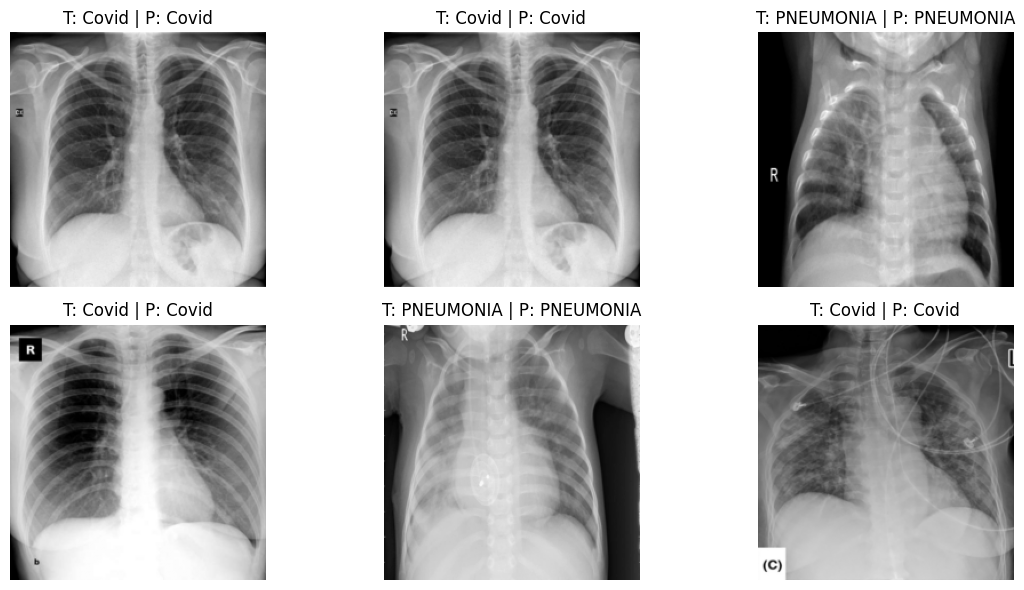

In [ ]:
# ─── Visualization ─────────────────────────────────────────────────────
def imshow(img_tensor, title):
    img = img_tensor.squeeze().cpu().numpy()
    img = img * 0.5 + 0.5  # Unnormalize
    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis('off')

inputs, labels = next(iter(val_loader))
inputs, labels = inputs.to(device), labels.to(device)
outputs = model(inputs)
preds = torch.argmax(outputs, 1)

plt.figure(figsize=(12, 6))
for i in range(6):
    plt.subplot(2, 3, i+1)
    title = f"T: {class_names[labels[i]]} | P: {class_names[preds[i]]}"
    imshow(inputs[i], title)
plt.tight_layout()
plt.show()

In [ ]:
# ─── Predict a Single Image ────────────────────────────────────────────
def predict_image(image_path, model, transform):
    model.eval()
    img = Image.open(image_path).convert('L')
    img = transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(img)
        pred = torch.argmax(output, 1)
    return class_names[pred.item()]



In [ ]:
# Usage:
result = predict_image('/content/drive/MyDrive/person1_virus_8 (1).jpeg', model, transform)

print("Prediction:", result)

Prediction: PNEUMONIA
